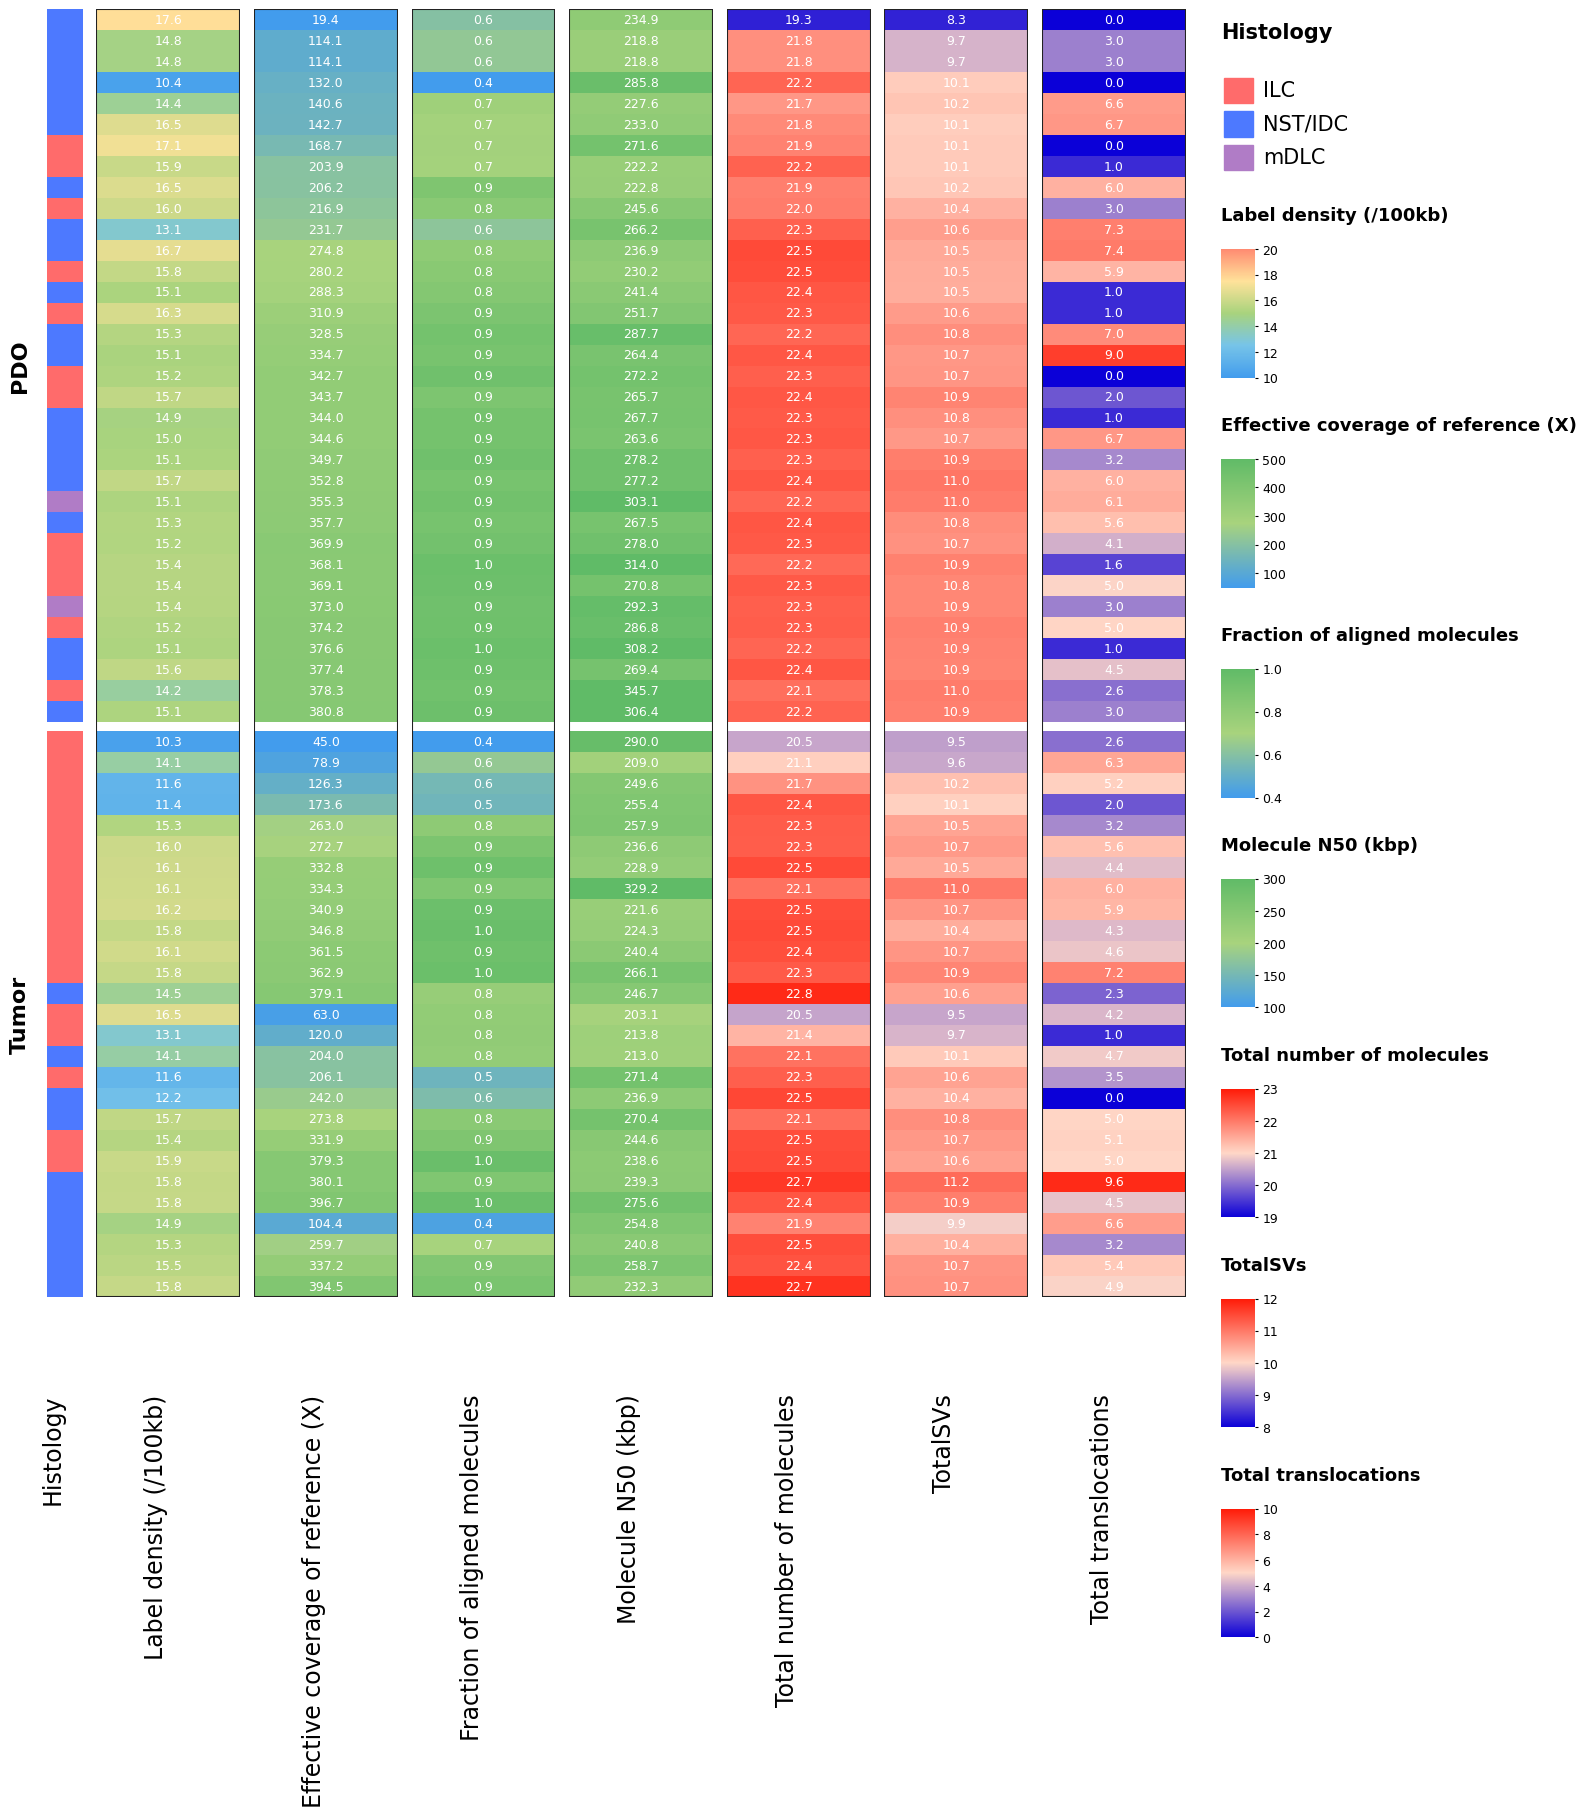

Saved PNG: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/QC/QC.png
Saved PDF: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/QC/QC.pdf


In [4]:
"""QC overview heatmap""

from pathlib import Path
import csv
import re

import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap, Normalize
import numpy as np
import pandas as pd


# -----------------------------------------------------------------------------
# Input and output paths
# -----------------------------------------------------------------------------
HERE = Path("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/QC")

QC_FILE = HERE / "QC_overview.tsv"
ANNOTATION_FILE = HERE / "Annotation.csv"

OUT_PNG = HERE / "QC.png"
OUT_PDF = HERE / "QC.pdf"


# -----------------------------------------------------------------------------
# Display order: PDO first, then Tumor
# -----------------------------------------------------------------------------
DISPLAY_GROUPS = {
    "PDO": [
        "IPM-BO-109", "IPM-BO-168", "IPM-BO-181", "IPM-BO-148",
        "IPM-BO-085", "IPM-BO-100", "IPM-BO-189", "IPM-BO-021",
        "IPM-BO-186", "IPM-BO-174", "IPM-BO-129", "IPM-BO-075",
        "IPM-BO-086", "IPM-BO-127", "IPM-BO-167", "IPM-BO-108",
        "IPM-BO-111", "IPM-BO-069", "IPM-BO-184", "IPM-BO-102",
        "IPM-BO-123", "IPM-BO-043", "IPM-BO-056", "IPM-BO-084",
        "IPM-BO-124", "IPM-BO-153", "IPM-BO-041", "IPM-BO-046",
        "IPM-BO-071", "IPM-BO-055", "IPM-BO-126", "IPM-BO-019",
        "IPM-BO-077", "IPM-BO-030"
    ],

    "Tumor": [
        "TP08-2202", "TP12-880", "TP11-1516", "TP11-1780",
        "TP07-626", "TP05-232", "TP14-586", "TP15-M509",
        "TP04-104", "TP14-385", "TP05-726", "TP13-820",
        "TP11-896", "TP14-79", "TP16-M744", "TP13-1591",
        "TP10-1655", "TP12-233", "TP13-1334", "TP12-813",
        "TP17-M606", "TP11-2004", "TP12-1058", "TP19-M6",
        "TP21-M598", "TP21-M3", "TP18-M733"
    ]
}


# QC metric panels:
# metric name in QC overview file, displayed label, colour range, colours
PANELS = [
    (
        "Label density (/100kb)",
        "Label density (/100kb)",
        (10, 20),
        ["#429ced", "#77c4e8", "#a8d37d", "#ffe29a", "#ff8a71"]
    ),
    (
        "Effective coverage of reference (X)",
        "Effective coverage of reference (X)",
        (50, 500),
        ["#429ced", "#a8d37d", "#60bb67"]
    ),
    (
        "Fraction of aligned molecules",
        "Fraction of aligned molecules",
        (0.4, 1.0),
        ["#429ced", "#a8d37d", "#60bb67"]
    ),
    (
        "Molecule N50 (kbp)",
        "Molecule N50 (kbp)",
        (100, 300),
        ["#429ced", "#a8d37d", "#60bb67"]
    ),
    (
        "Total number of molecules",
        "Total number of molecules",
        (19, 23),
        ["#0b00d8", "#ffd7c7", "#ff1b08"]
    ),
    (
        "TotalSVs",
        "TotalSVs",
        (8, 12),
        ["#0b00d8", "#ffd7c7", "#ff1b08"]
    ),
    (
        "Total_translocations",
        "Total translocations",
        (0, 10),
        ["#0b00d8", "#ffd7c7", "#ff1b08"]
    )
]


def clean_sample_id(sample):
    """Remove whitespace and normalize TP14-079 to TP14-79."""
    sample = str(sample).strip()
    return re.sub(r"TP(\d+)-(0+)(\d+)$", r"TP\1-\3", sample)


def load_qc_table():
    """Read QC overview TSV, which has sample IDs in the first row."""
    with QC_FILE.open(newline="") as handle:
        rows = list(csv.reader(handle, delimiter="\t"))

    sample_ids = [clean_sample_id(x) for x in rows[0]]

    qc = pd.DataFrame(
        {
            row[0]: pd.to_numeric(row[1:], errors="coerce")
            for row in rows[1:]
        },
        index=sample_ids
    )

    return qc


def main():
    # -------------------------------------------------------------------------
    # Load QC and histology annotation
    # -------------------------------------------------------------------------
    qc = load_qc_table()

    annotation = pd.read_csv(ANNOTATION_FILE, encoding="utf-8-sig")
    annotation["sample_key"] = annotation["SampleID"].map(clean_sample_id)

    histology_dict = annotation.set_index("sample_key")["Histology"].to_dict()

    ordered_samples = [
        sample
        for group_samples in DISPLAY_GROUPS.values()
        for sample in group_samples
    ]

    missing_samples = [
        sample for sample in ordered_samples
        if sample not in qc.index
    ]

    if missing_samples:
        raise ValueError(
            "These samples are absent from QC_overview.tsv:\n"
            + "\n".join(missing_samples)
        )

    qc = qc.loc[ordered_samples].copy()

    # -------------------------------------------------------------------------
    # Histology annotation
    # -------------------------------------------------------------------------
    hist_categories = ["ILC", "NST", "mDLC", "Unknown"]

    hist_colors = {
        "ILC": "#FF6B6B",      # red
        "NST": "#4D79FF",      # blue
        "mDLC": "#B07CC6",     # purple
        "Unknown": "#BDBDBD"   # grey
    }

    hist_values = [
        hist_categories.index(histology_dict.get(sample, "Unknown"))
        for sample in ordered_samples
    ]

    # -------------------------------------------------------------------------
    # Transform selected QC values for visualisation
    # -------------------------------------------------------------------------
    transformed = pd.DataFrame(index=qc.index)

    for metric_name, _, _, _ in PANELS:
        values = qc[metric_name].astype(float)

        if metric_name in {"Total number of molecules", "TotalSVs"}:
            values = np.log2(values)

        elif metric_name == "Total_translocations":
            values = np.log2(values + 1)

        transformed[metric_name] = values

    # -------------------------------------------------------------------------
    # Row positions and group gap
    # -------------------------------------------------------------------------
    n_samples = len(ordered_samples)

    group_boundaries = np.cumsum(
        [len(samples) for samples in DISPLAY_GROUPS.values()]
    )[:-1]

    gap_size = 0.45

    y_positions = np.arange(n_samples, dtype=float)

    for boundary in group_boundaries:
        y_positions[boundary:] += gap_size

    total_height = y_positions[-1] + 1

    # -------------------------------------------------------------------------
    # Create figure
    # -------------------------------------------------------------------------
    fig = plt.figure(figsize=(16, 16), facecolor="white")

    gs = fig.add_gridspec(
        nrows=1,
        ncols=10,
        width_ratios=[0.25, 1, 1, 1, 1, 1, 1, 1, 0.05, 2.35],
        left=0.04,
        right=0.985,
        bottom=0.18,
        top=0.985,
        wspace=0.10
    )

    axes = [fig.add_subplot(gs[0, i]) for i in range(8)]
    sample_label_ax = fig.add_subplot(gs[0, 8])
    legend_ax = fig.add_subplot(gs[0, 9])

    # -------------------------------------------------------------------------
    # Histology annotation strip
    # -------------------------------------------------------------------------
    histology_ax = axes[0]

    for y, hist_index in zip(y_positions, hist_values):
        histology_ax.add_patch(
            plt.Rectangle(
                (0, y),
                width=1,
                height=1,
                color=hist_colors[hist_categories[hist_index]],
                ec="none"
            )
        )

    histology_ax.set_xlim(0, 1)
    histology_ax.set_ylim(total_height, 0)
    histology_ax.axis("off")

    # -------------------------------------------------------------------------
    # QC heatmap panels
    # -------------------------------------------------------------------------
    for panel_index, (metric_name, x_label, limits, colors) in enumerate(
        PANELS,
        start=1
    ):
        ax = axes[panel_index]

        cmap = LinearSegmentedColormap.from_list(metric_name, colors)
        norm = Normalize(vmin=limits[0], vmax=limits[1], clip=True)

        for y, value in zip(y_positions, transformed[metric_name]):

            ax.add_patch(
                plt.Rectangle(
                    (0, y),
                    width=1,
                    height=1,
                    color=cmap(norm(value)),
                    ec="none"
                )
            )

            ax.text(
                0.5,
                y + 0.5,
                f"{value:.1f}",
                ha="center",
                va="center",
                color="white",
                fontsize=9
            )

        ax.add_patch(
            plt.Rectangle(
                (0, 0),
                width=1,
                height=total_height,
                fill=False,
                ec="#222222",
                lw=1.5
            )
        )

        ax.set_xlim(0, 1)
        ax.set_ylim(total_height, 0)
        ax.axis("off")

        ax.text(
            0.5,
            -0.075,
            x_label,
            rotation=90,
            ha="right",
            va="top",
            fontsize=17,
            transform=ax.transAxes,
            clip_on=False
        )

    # -------------------------------------------------------------------------
    # Left-side PDO and Tumor labels
    # -------------------------------------------------------------------------
    start_index = 0

    for group_name, group_samples in DISPLAY_GROUPS.items():

        end_index = start_index + len(group_samples) - 1

        centre_y = (
            y_positions[start_index] +
            y_positions[end_index] +
            1
        ) / 2

        histology_ax.text(
            -0.74,
            centre_y,
            group_name,
            rotation=90,
            ha="center",
            va="center",
            fontsize=16,
            fontweight="bold",
            transform=histology_ax.transData,
            clip_on=False
        )

        start_index += len(group_samples)

    histology_ax.text(
        0.5,
        -0.075,
        "Histology",
        rotation=90,
        ha="right",
        va="top",
        fontsize=17,
        transform=histology_ax.transAxes,
        clip_on=False
    )

    # -------------------------------------------------------------------------
    # Sample ID labels
    # -------------------------------------------------------------------------
    sample_label_ax.axis("off")
    # -------------------------------------------------------------------------
    # Legends
    # -------------------------------------------------------------------------
    legend_ax.axis("off")

    legend_y = 0.99

    legend_ax.text(
        0.0,
        legend_y,
        "Histology",
        transform=legend_ax.transAxes,
        fontsize=15,
        fontweight="bold",
        va="top"
    )

    legend_y -= 0.045

    for category in ["ILC", "NST", "mDLC"]:

        legend_ax.add_patch(
            plt.Rectangle(
                (0.01, legend_y - 0.018),
                0.085,
                0.02,
                transform=legend_ax.transAxes,
                color=hist_colors[category],
                clip_on=False
            )
        )

        display_name = "NST/IDC" if category == "NST" else category

        legend_ax.text(
            0.125,
            legend_y - 0.008,
            display_name,
            transform=legend_ax.transAxes,
            fontsize=15,
            va="center"
        )

        legend_y -= 0.026

    legend_y -= 0.02

    for metric_name, legend_label, limits, colors in PANELS:

        legend_ax.text(
            0.0,
            legend_y,
            legend_label,
            transform=legend_ax.transAxes,
            fontsize=13,
            fontweight="bold",
            va="top"
        )

        legend_y -= 0.028

        cax = legend_ax.inset_axes(
            [0.0, legend_y - 0.105, 0.10, 0.10]
        )

        cmap = LinearSegmentedColormap.from_list(metric_name, colors)

        colorbar = fig.colorbar(
            mpl.cm.ScalarMappable(
                norm=Normalize(vmin=limits[0], vmax=limits[1]),
                cmap=cmap
            ),
            cax=cax,
            orientation="vertical"
        )

        colorbar.ax.tick_params(labelsize=9, length=2)
        colorbar.outline.set_visible(False)

        legend_y -= 0.135

    # -------------------------------------------------------------------------
    # Save output
    # -------------------------------------------------------------------------
    fig.savefig(
        OUT_PNG,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        OUT_PDF,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()

    print(f"Saved PNG: {OUT_PNG}")
    print(f"Saved PDF: {OUT_PDF}")


if __name__ == "__main__":
    main()

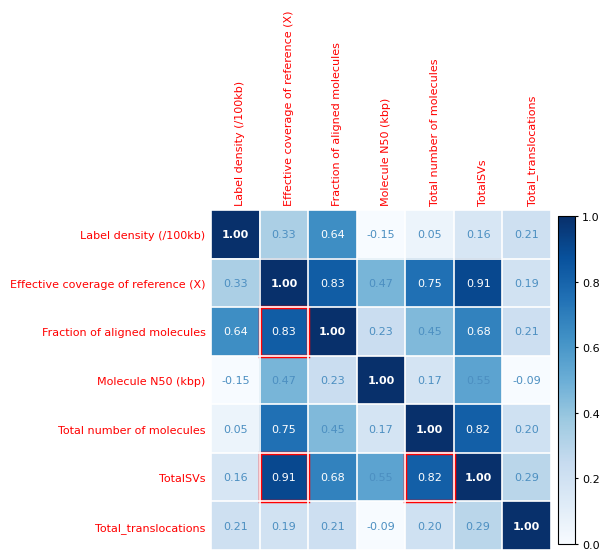

Saved PNG: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/QC/QC_metric_correlation_heatmap.png
Saved PDF: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/QC/QC_metric_correlation_heatmap.pdf


In [6]:
"""Correlation heatmap for seven optical genome mapping QC metrics."""

from pathlib import Path
import csv

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd


HERE = Path("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/QC")

QC_FILE = HERE / "QC_overview.tsv"
OUT_PNG = HERE / "QC_metric_correlation_heatmap.png"
OUT_PDF = HERE / "QC_metric_correlation_heatmap.pdf"

METRICS = [
    "Label density (/100kb)",
    "Effective coverage of reference (X)",
    "Fraction of aligned molecules",
    "Molecule N50 (kbp)",
    "Total number of molecules",
    "TotalSVs",
    "Total_translocations",
]


def load_qc_table():
    """Read the QC TSV, whose first row contains sample IDs."""
    with QC_FILE.open(newline="") as handle:
        rows = list(csv.reader(handle, delimiter="\t"))

    return pd.DataFrame(
        {row[0]: pd.to_numeric(row[1:], errors="coerce") for row in rows[1:]}
    )


def main():
    qc = load_qc_table()

    # Match the reference figure: these count variables are assessed on log2 scale.
    data = qc[METRICS].copy()
    data["Total number of molecules"] = np.log2(data["Total number of molecules"])
    data["TotalSVs"] = np.log2(data["TotalSVs"])
    data["Total_translocations"] = np.log2(data["Total_translocations"] + 1)

    correlation = data.corr(method="pearson")

    fig, ax = plt.subplots(figsize=(6.2, 6.2), facecolor="white")
    image = ax.imshow(
        correlation,
        cmap="Blues",
        norm=Normalize(vmin=0, vmax=1),
        aspect="equal",
    )

    n_metrics = len(METRICS)
    ax.set_xticks(np.arange(n_metrics))
    ax.set_yticks(np.arange(n_metrics))
    ax.set_xticklabels(METRICS, color="red", fontsize=8)
    ax.set_yticklabels(METRICS, color="red", fontsize=8)
    ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False, length=0, pad=4)
    plt.setp(ax.get_xticklabels(), rotation=90, ha="left", va="bottom")

    # White grid lines match the compact annotated-matrix style.
    ax.set_xticks(np.arange(-0.5, n_metrics, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_metrics, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.2)
    ax.tick_params(which="minor", bottom=False, left=False)

    # Numeric Pearson r values.  Dark cells receive white text for contrast.
    for i in range(n_metrics):
        for j in range(n_metrics):
            r = correlation.iloc[i, j]
            text_colour = "white" if r >= 0.55 else "#4c8fc1"
            ax.text(j, i, f"{r:.2f}", ha="center", va="center",
                    fontsize=8, fontweight="bold" if i == j else "normal",
                    color=text_colour)

            # Highlight strong non-diagonal correlations, as in the reference.
            if i > j and abs(r) >= 0.80:
                ax.add_patch(
                    Rectangle((j - 0.5, i - 0.5), 1, 1,
                              fill=False, edgecolor="red", linewidth=2.5)
                )

    for spine in ax.spines.values():
        spine.set_visible(False)

    colorbar = fig.colorbar(image, ax=ax, fraction=0.045, pad=0.02)
    colorbar.ax.tick_params(labelsize=8, length=2)
    colorbar.set_ticks(np.arange(0, 1.01, 0.2))

    fig.tight_layout()
    fig.savefig(OUT_PNG, dpi=300, bbox_inches="tight", facecolor="white")
    fig.savefig(OUT_PDF, bbox_inches="tight", facecolor="white")
    plt.show()

    print(f"Saved PNG: {OUT_PNG}")
    print(f"Saved PDF: {OUT_PDF}")


if __name__ == "__main__":
    main()

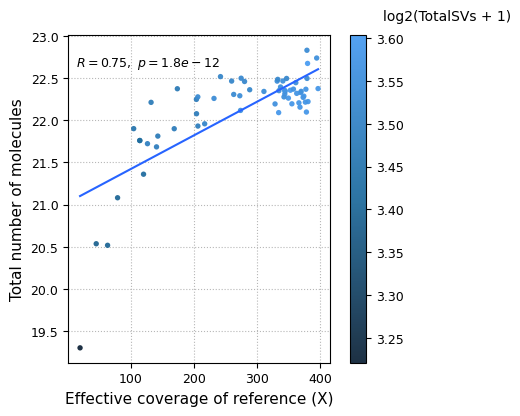

Pearson r = 0.753; p = 1.751e-12
Saved PNG: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/QC/QC_coverage_vs_total_molecules.png
Saved PDF: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/QC/QC_coverage_vs_total_molecules.pdf


In [8]:
"""QC association plot: effective coverage versus total molecules."""

from pathlib import Path
import csv

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
import numpy as np
import pandas as pd
from scipy.stats import linregress, pearsonr


HERE = Path("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/QC")
QC_FILE = HERE / "QC_overview.tsv"
OUT_PNG = HERE / "QC_coverage_vs_total_molecules.png"
OUT_PDF = HERE / "QC_coverage_vs_total_molecules.pdf"


def load_qc_table():
    """Read QC TSV with sample IDs in the first row."""
    with QC_FILE.open(newline="") as handle:
        rows = list(csv.reader(handle, delimiter="\t"))
    return pd.DataFrame(
        {row[0]: pd.to_numeric(row[1:], errors="coerce") for row in rows[1:]}
    )


def main():
    qc = load_qc_table()

    x = qc["Effective coverage of reference (X)"].astype(float)
    y = np.log2(qc["Total number of molecules"].astype(float))

    # This intentionally reproduces the reference colour bar (approximately
    # 3.3–3.6): TotalSVs is first log2-transformed, then log2-transformed again.
    colour = np.log2(np.log2(qc["TotalSVs"].astype(float)) + 1)
    # Keep the reference-figure label, while retaining its displayed scale.
    colour_label = "log2(TotalSVs + 1)"

    plot_data = pd.DataFrame({"x": x, "y": y, "colour": colour}).dropna()
    x = plot_data["x"]
    y = plot_data["y"]
    colour = plot_data["colour"]

    r, p_value = pearsonr(x, y)
    fit = linregress(x, y)
    x_line = np.linspace(x.min(), x.max(), 200)
    y_line = fit.intercept + fit.slope * x_line

    fig, ax = plt.subplots(figsize=(5.2, 4.2), facecolor="white")
    cmap = LinearSegmentedColormap.from_list(
        "dark_to_light_blue", ["#12263a", "#216d9e", "#4b9df2"]
    )

    scatter = ax.scatter(
        x, y,
        c=colour,
        cmap=cmap,
        norm=Normalize(vmin=colour.min(), vmax=colour.max()),
        s=15,
        linewidths=0,
        alpha=0.95,
    )
    ax.plot(x_line, y_line, color="#2764ff", linewidth=1.5)

    ax.text(
        0.03, 0.94,
        rf"$R = {r:.2f},\ p = {p_value:.1e}$",
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=9, fontstyle="italic",
    )

    ax.set_xlabel("Effective coverage of reference (X)", fontsize=11)
    ax.set_ylabel("Total number of molecules", fontsize=11)
    ax.tick_params(labelsize=9)
    ax.grid(True, linestyle=":", color="#b7b7b7", linewidth=0.8)
    ax.set_axisbelow(True)

    colorbar = fig.colorbar(scatter, ax=ax, pad=0.06)
    colorbar.set_label(colour_label, fontsize=10, rotation=0, labelpad=31, y=1.08)
    colorbar.ax.tick_params(labelsize=9)

    fig.tight_layout()
    fig.savefig(OUT_PNG, dpi=300, bbox_inches="tight", facecolor="white")
    fig.savefig(OUT_PDF, bbox_inches="tight", facecolor="white")
    plt.show()

    print(f"Pearson r = {r:.3f}; p = {p_value:.3e}")
    print(f"Saved PNG: {OUT_PNG}")
    print(f"Saved PDF: {OUT_PDF}")


if __name__ == "__main__":
    main()